# How sure are we? Two open ensembles, side by side 🎲
### ECMWF free & open data · IFS ENS and AIFS ENS · no account needed

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/unicef/ensemble_probability.ipynb)

A single forecast says *what* is most likely. An **ensemble** of 50 forecasts, each started from slightly different
conditions, says *how likely*. That is the number anticipatory-action plans are built on: act when the chance of
heavy rain passes a threshold.

ECMWF runs two ensembles and both are open data: the physics-based **IFS ENS** and the machine-learning **AIFS ENS**.
This notebook maps, from each, the chance of more than 50 mm of rain in the next five days.

*In Google Colab? Press **Runtime → Run all**.*

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes ~1 minute.
!pip install -q "earthkit-data[ecmwf-opendata]" earthkit-plots

In [2]:
import pyproj                     # import before earthkit.data (avoids a crash at exit)
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.patheffects as pe
import numpy as np

## 1 · Choose the place, the window and the threshold

In [3]:
# Countries where UNICEF responded to, or prepared for, weather and climate hazards in 2025-26
PLACES = {
    "Somalia":     dict(domain=[36.5, 51.6, -2.5, 12.5],      # with the Ethiopian highlands that feed the rivers
                        cities=[("Mogadishu", 2.046, 45.318), ("Beledweyne", 4.736, 45.204), ("Baidoa", 3.114, 43.650),
                                ("Kismayo", -0.358, 42.545), ("Garowe", 8.406, 48.483), ("Hargeisa", 9.560, 44.065)]),
    "Mozambique":  dict(domain=[30.0, 41.0, -27.0, -10.3],
                        cities=[("Maputo", -25.966, 32.583), ("Xai-Xai", -25.052, 33.644), ("Beira", -19.844, 34.839),
                                ("Nampula", -15.116, 39.266)]),
    "Malawi":      dict(domain=[32.0, 36.5, -17.4, -9.2],
                        cities=[("Lilongwe", -13.963, 33.775), ("Blantyre", -15.786, 35.006), ("Nsanje", -16.920, 35.262)]),
    "Madagascar":  dict(domain=[42.8, 51.0, -26.0, -11.7],
                        cities=[("Antananarivo", -18.879, 47.508), ("Toamasina", -18.149, 49.402), ("Toliara", -23.354, 43.669)]),
    "Philippines": dict(domain=[116.5, 127.0, 4.5, 21.0],
                        cities=[("Manila", 14.600, 120.984), ("Virac", 13.580, 124.230), ("Tacloban", 11.244, 125.004),
                                ("Cebu", 10.316, 123.891), ("Davao", 7.190, 125.455)]),
    "Honduras":    dict(domain=[-89.5, -83.0, 12.8, 16.6],
                        cities=[("Tegucigalpa", 14.072, -87.192), ("San Pedro Sula", 15.506, -88.025), ("Choluteca", 13.300, -87.193)]),
    "Chad":        dict(domain=[13.4, 24.1, 7.4, 23.5],
                        cities=[("N'Djamena", 12.134, 15.055), ("Moussoro", 13.641, 16.490), ("Mao", 14.119, 15.313)]),
    "Pakistan":    dict(domain=[60.8, 77.9, 23.6, 37.1],
                        cities=[("Islamabad", 33.684, 73.048), ("Peshawar", 34.015, 71.524), ("Lahore", 31.520, 74.359),
                                ("Karachi", 24.861, 67.010)]),
}

PLACE     = "Philippines"
DAYS      = 5        # rain added up over the next DAYS days (1 to 15)
THRESHOLD = 50       # mm

## 2 · Get both ensembles (ECMWF open data, 0.25°)

50 members from each model, rainfall accumulated to `24 × DAYS` hours. About 30 MB per model.

In [4]:
def members(model):
    fl = ekd.from_source("ecmwf-open-data", model=model, stream="enfo", type="pf", param="tp",
                         step=24 * DAYS).to_fieldlist()
    da = fl.to_xarray()["tp"]                                               # dims: member, latitude, longitude
    scale = 1000 if fl[0].get("parameter.units") == "m" else 1              # metres -> mm when needed
    return fl, da * scale

ifs, ifs_mm = members("ifs")
aifs, aifs_mm = members("aifs-ens")
start, end = ifs[0].time.base_datetime(), ifs[0].time.valid_datetime()
print(f"{ifs_mm.sizes['member']} IFS and {aifs_mm.sizes['member']} AIFS members, run {start:%d %B %Y %H} UTC")

By downloading data from the ECMWF open data dataset, you agree to the terms: Attribution 4.0 International (CC BY 4.0). Please attribute ECMWF when downloading this data.


50 IFS and 50 AIFS members, run 18 November 2026 00 UTC


## 3 · Turn 50 forecasts into a probability

At every grid point, count the members with more than `THRESHOLD` mm. (Plain xarray: a probability of exceedance
is one line.)

In [5]:
prob = {"IFS ENS (physics)": (ifs_mm > THRESHOLD).mean("member") * 100,
        "AIFS ENS (machine learning)": (aifs_mm > THRESHOLD).mean("member") * 100}
for k, p in prob.items():
    p.attrs = {"units": "%", "long_name": f"Chance of more than {THRESHOLD} mm"}

## 4 · Map both

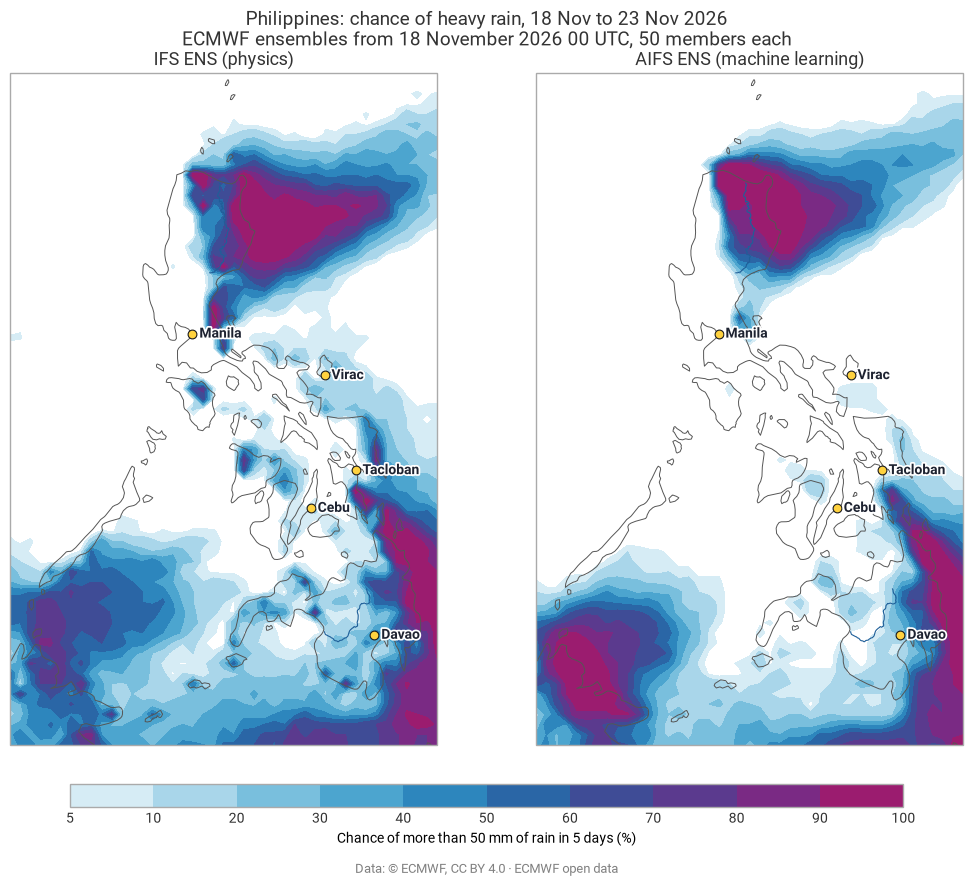

In [6]:
def label_cities(chart, cities, ink="#1d2230", halo="white"):
    for name, lat, lon in cities:
        chart.scatter(x=[lon], y=[lat], s=40, color="#ffd23f", edgecolors="#1a1a1a", linewidths=0.8, zorder=10)
        chart.ax.text(lon, lat, f"  {name}", ha="left", va="center", fontsize=10, fontweight="bold", color=ink, zorder=11,
                      transform=ccrs.PlateCarree(), path_effects=[pe.withStroke(linewidth=2.5, foreground=halo)])

P = PLACES[PLACE]
style = ekp.styles.Style(levels=[5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100],
                         colors=["#d6ecf5", "#a9d6ea", "#79bfdd", "#4ca5cf", "#2d86bd", "#2a66a6",
                                 "#3f4c96", "#5b3a8e", "#7a2a84", "#9b1c6f"], extend="neither")
fig = ekp.Figure(rows=1, columns=2, figsize=(10.5, 8))
for col, (label, p) in enumerate(prob.items()):
    m = fig.add_map(0, col, domain=P["domain"])
    m.contourf(p, style=style)
    m.ax.add_feature(cfeature.RIVERS.with_scale("10m"), edgecolor="#1f5f99", linewidth=0.8, zorder=4)
    m.borders(linewidth=0.7, color="#555555"); m.coastlines(linewidth=0.7)
    label_cities(m, P["cities"])
    m.title(label, fontsize=13)
fig.legend(label=f"Chance of more than {THRESHOLD} mm of rain in {DAYS} days (%)")
fig.title(f"{PLACE}: chance of heavy rain, {start:%d %b} to {end:%d %b %Y}\n"
          f"ECMWF ensembles from {start:%d %B %Y %H} UTC, 50 members each", fontsize=14)
fig.attribution("Data: © ECMWF, CC BY 4.0 · ECMWF open data")
fig.save("ensemble_probability.png")
fig.show()

## 5 · The numbers at each place

In [7]:
lat, lon = ifs[0].geography.latlons()
print(f"Chance of more than {THRESHOLD} mm in {DAYS} days")
print(f"{'':14}{'IFS ENS':>9}{'AIFS ENS':>10}")
for name, la, lo in P["cities"]:
    v = [float(p.sel(latitude=la, longitude=lo % 360 if p.longitude.max() > 180 else lo, method="nearest"))
         for p in prob.values()]
    print(f"{name:14}{v[0]:8.0f}%{v[1]:9.0f}%")

Chance of more than 50 mm in 5 days
                IFS ENS  AIFS ENS
Manila               0%        0%
Virac                6%        4%
Tacloban             2%        0%
Cebu                12%        0%
Davao               46%       24%


## 6 · Your turn 🌍

- **A different trigger?** Change `THRESHOLD` (20, 100 mm …) and `DAYS`.
- **Another country?** `PLACE = "Somalia"`, `"Mozambique"`, `"Malawi"` …
- **Where do the two models agree?** Try `prob["IFS ENS (physics)"] - prob["AIFS ENS (machine learning)"]`.

### Data & licence
ECMWF Open Data is free under **Creative Commons CC-BY-4.0**:
`© ECMWF · Source: www.ecmwf.int · CC-BY-4.0 and ECMWF Terms of Use`. No account, no key.

[ECMWF open data](https://www.ecmwf.int/en/forecasts/datasets/open-data) ·
[earthkit](https://earthkit.ecmwf.int) · [earthkit-data](https://earthkit-data.readthedocs.io) ·
[earthkit-plots](https://earthkit-plots.readthedocs.io)